# From source cells to representative classes

A barcode describes when a feature lives. To understand the input behind it, we often need to look at the cells themselves. Which squares have appeared? Which edges bound a selected square? Does an apparent intersection belong to the complex, or only to its drawing?

This guide follows a small image through those questions, then tries a point cloud and a periodic example. It assumes the workflow in [A hole appears and disappears](ring.ipynb); the [installation page](../src/start/install.md) supplies the Julia setup. We inspect the finite filtered complex before asking for its homology or encoding. A direct ordinary-persistence computation can use the same complex without constructing an `EncodingResult`.


In [1]:
import TamerOp as OP
import CairoMakie
CairoMakie.activate!(type="png", px_per_unit=1);


## See the cells that are present

Use the same image as the ring lesson. Entries grade **square cells**: the eight surrounding squares enter at zero, while the center enters at five. Their edges and vertices enter as soon as an incident square does.

`filtered_complex` retains this cell model, its geometry and its appearance grades. It does not compute homology or choose a cycle representative. Its default picture shows the first appearance parameter.


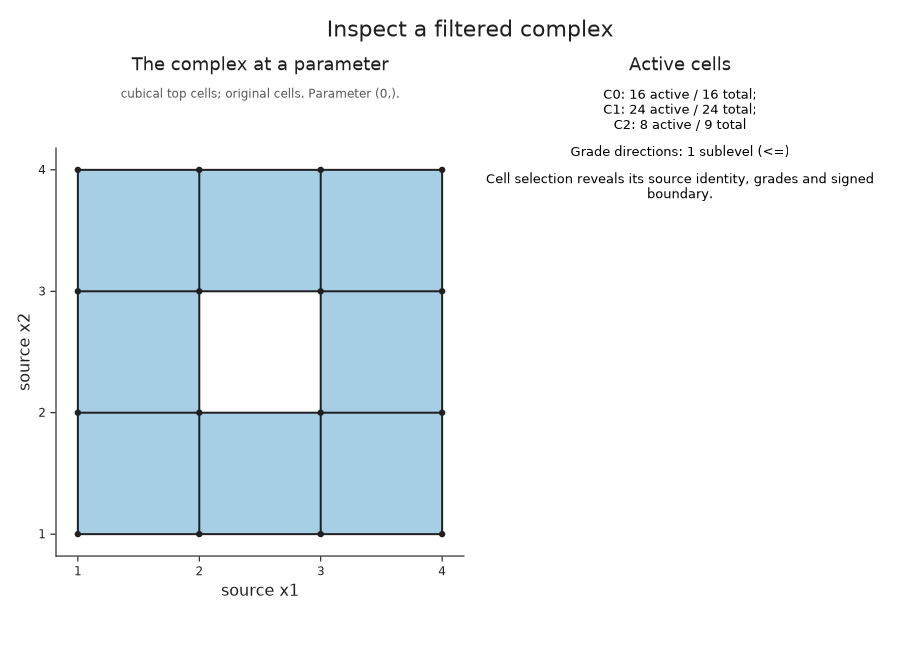

In [2]:
values = [0 0 0;
          0 5 0;
          0 0 0]
cells = OP.filtered_complex(values)
OP.visualize(cells)


The hole is now visible in a cell complex, with its edges and vertices. The coordinates number the grid in array-axis order: the first array index is the first geometric axis. They are not a photograph's row-down display convention.

Move to the center's appearance grade. Before running the next cell, predict which cell counts change. The central square's boundary already belongs to the surrounding squares, so adding the square need not add any edge or vertex.


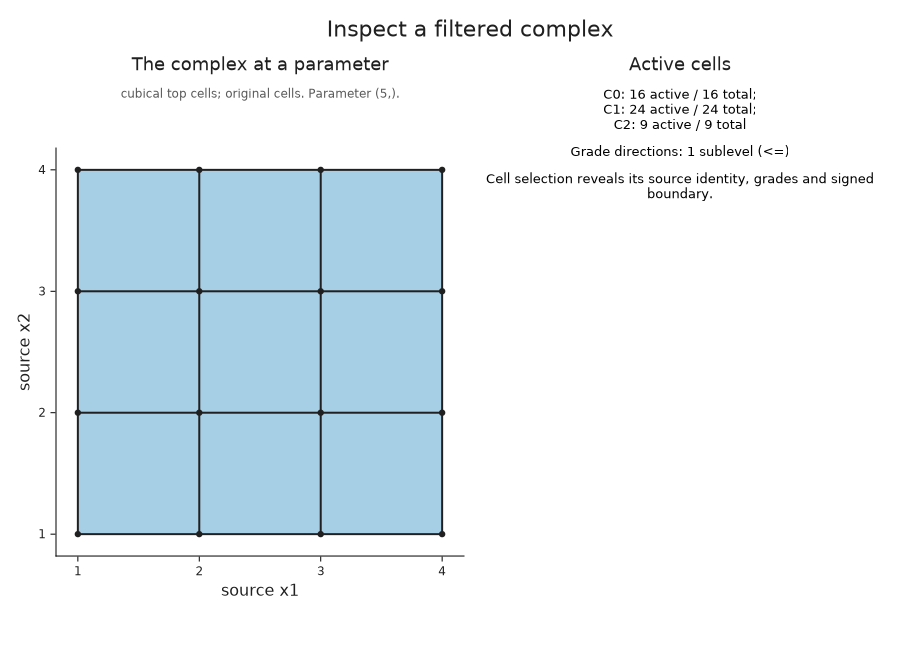

In [3]:
filled = OP.Advanced.visual_spec(cells; parameter=5)
@assert filled.metadata.active_counts == [16, 24, 9]
@assert OP.Advanced.visual_spec(cells; parameter=0).metadata.active_counts == [16, 24, 8]
OP.visualize(cells; parameter=5)


## Keep several parameter states in view

Changing a single parameter view is useful for exploration, but it can make us remember one picture while looking at another. A **parameter atlas** keeps a small declared set of states together, using the same source coordinates in each panel. It also computes the maps between states that the parameter order allows us to compare.

For the ring, take the states at zero and five and ask for degree-one homology. This calculation uses rational coefficients by default. The first state has a one-dimensional space of loop classes; the second has the zero space, because the central square has filled the hole.


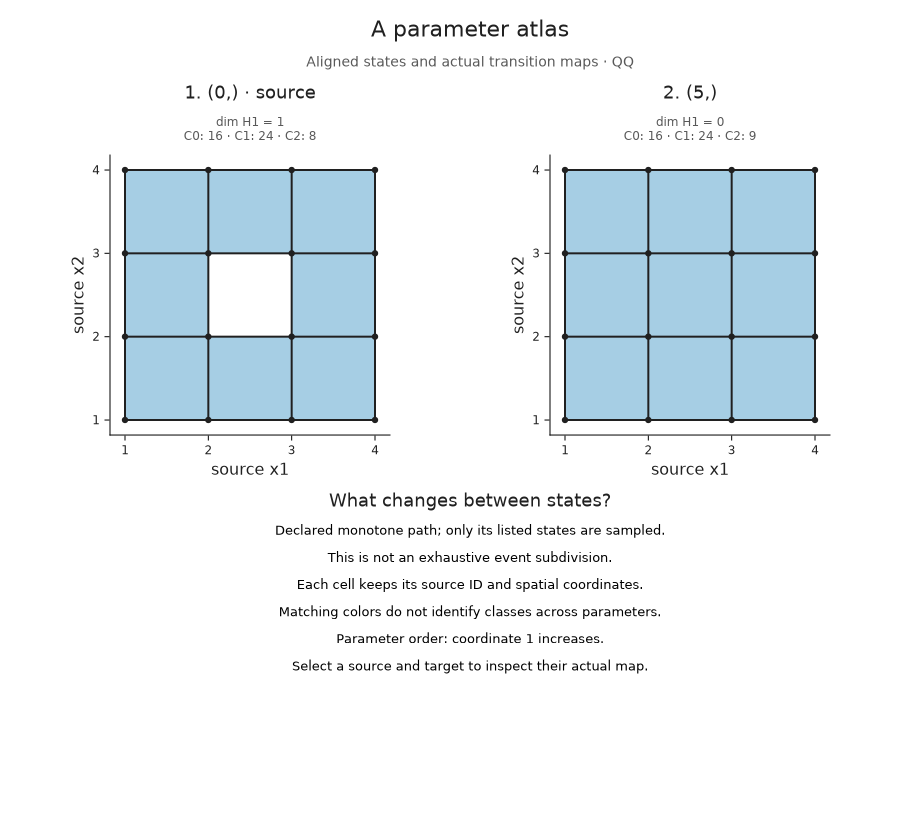

In [4]:
atlas = OP.parameter_atlas(cells; parameters=[0, 5], degree=1)
OP.visualize(atlas)


The atlas retains the actual linear map between these spaces. Its kernel consists of source classes sent to zero; its cokernel records target classes outside the image. These answer different questions from counting new cells. Here one square enters, one class vanishes, and no target class lies outside the image.

State indices follow our declared list: state 1 is parameter zero and state 2 is parameter five. They are not the global cell indices used below.


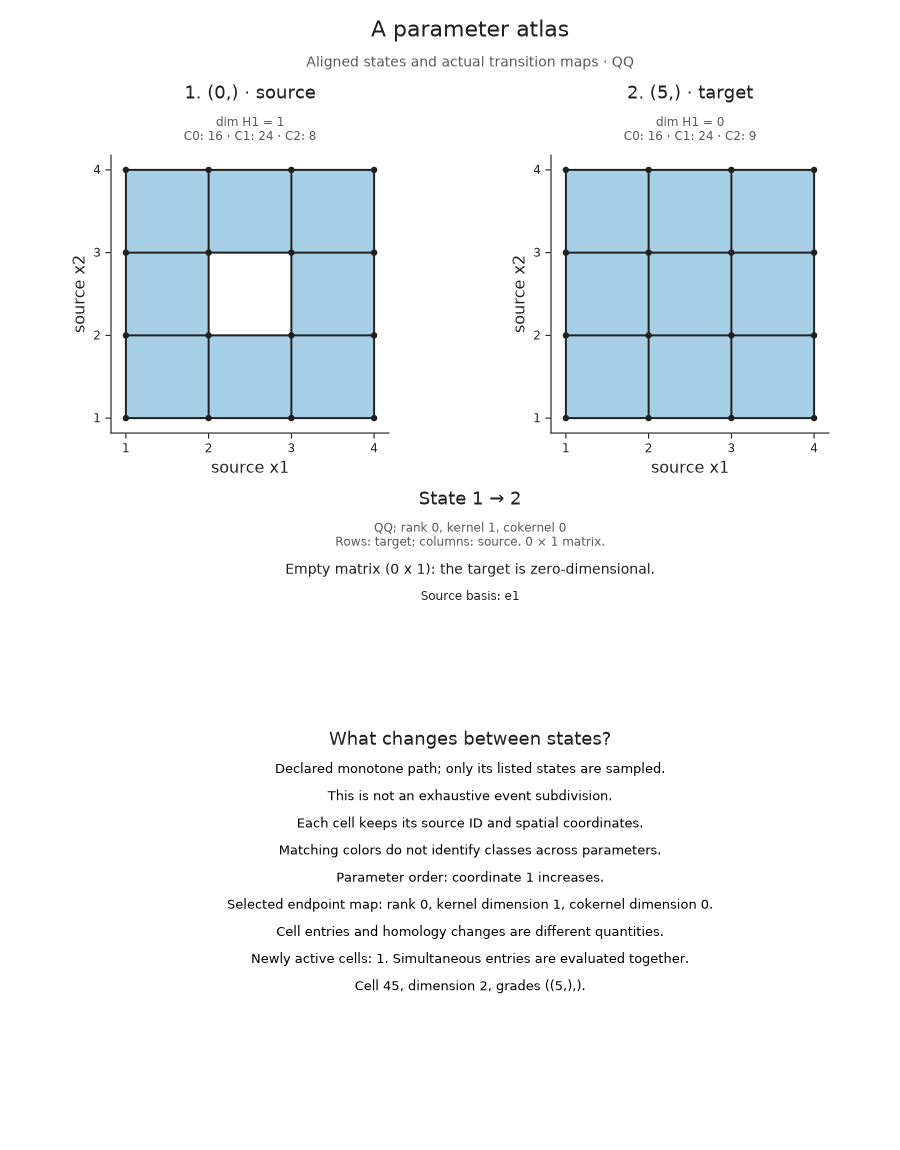

In [5]:
change = OP.Advanced.atlas_transition(atlas; source=1, target=2)
@assert size(change.matrix) == (0, 1)
@assert change.kernel_dimension == 1 && change.cokernel_dimension == 0
@assert [cell.index for cell in change.entries] == [45]
OP.visualize(atlas; target=2)


To see why the class vanishes, request witnesses when constructing the atlas. This retains a chosen cycle representing a kernel class and a chain at the target whose boundary is that cycle. The cycle need not be the shortest one, and its coefficients depend on the quotient basis chosen by the homology computation.


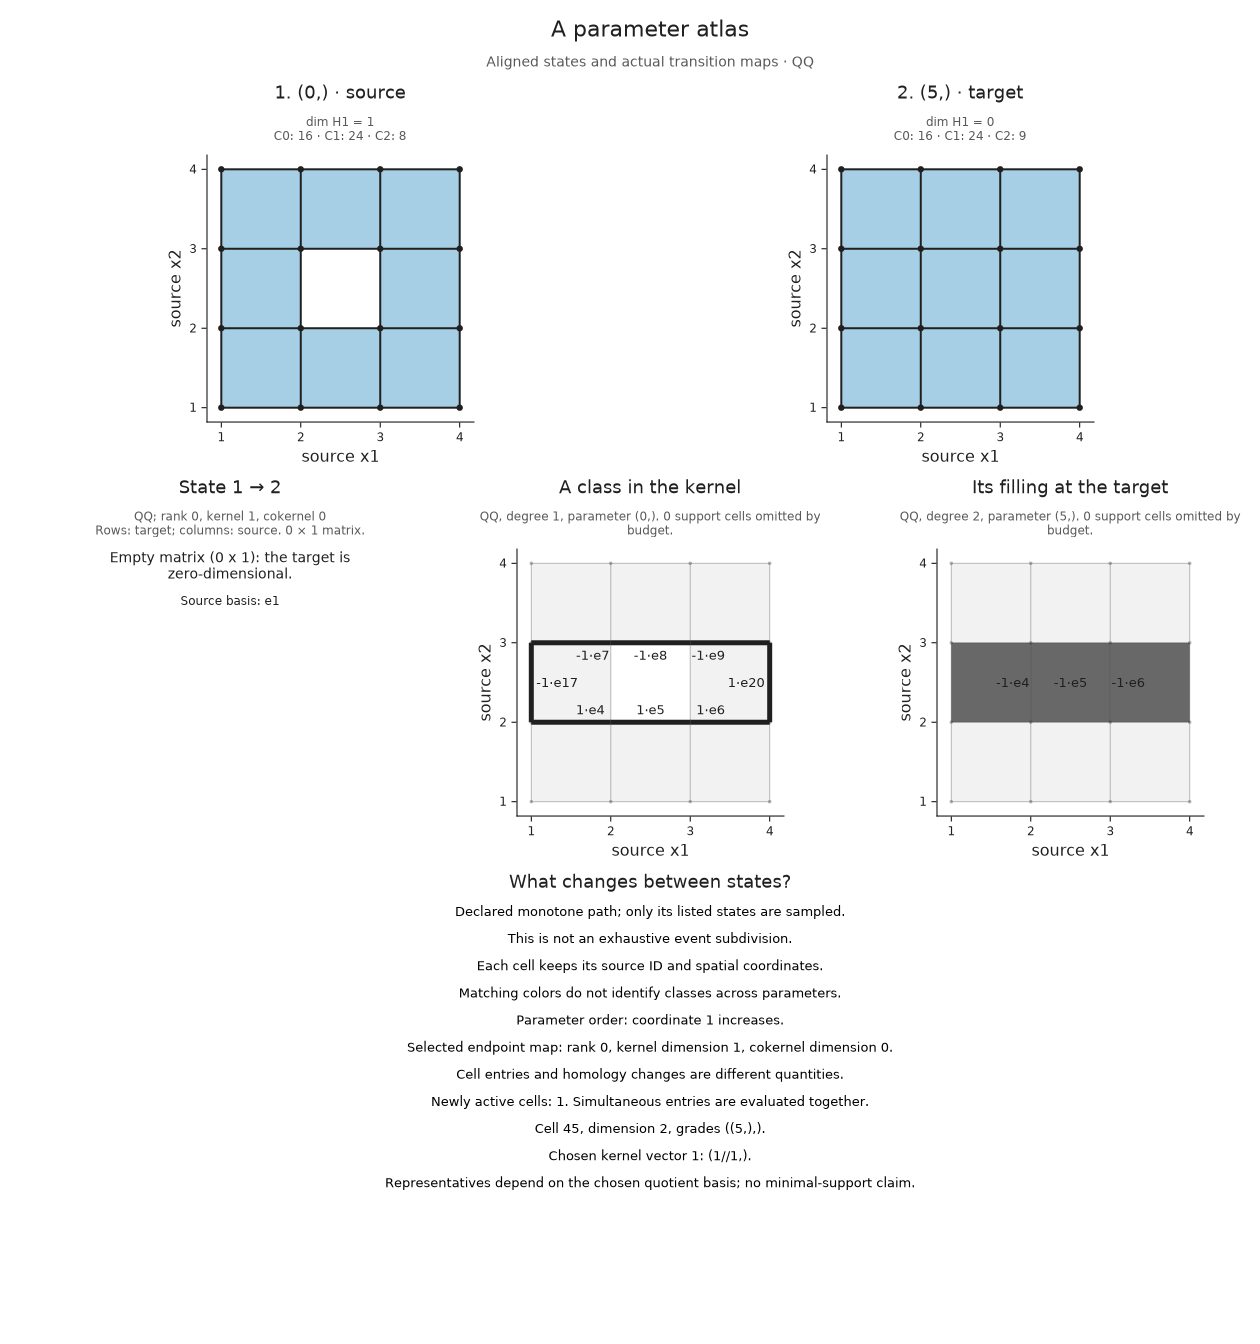

In [6]:
explained = OP.parameter_atlas(cells; parameters=[0, 5], degree=1, witnesses=true)
OP.visualize(explained; target=2, event=:kernel)


The atlas explains the map between its sampled endpoints. It does not certify that we sampled every event between them. If a loop both appears and fills between two samples, the endpoint spaces and their map can miss it entirely. On two parameters, a declared `grid=(xs, ys)` gives a contact sheet in coordinate order; incomparable grid points have no transition map, even when their space dimensions agree.

For linked exploration, `OP.visualize(OP.inspection_session(explained))` opens the atlas after loading WGLMakie. Select states with the panel, its keyboard-accessible button, or exact state indices, then choose cell entries or a retained class witness. The [visualization reference](../src/reference/visualization.md#parameter-atlases) describes finite-module and encoded-module inputs, budgets, and saved selections.


## Inspect a cell and its boundary

A global cell index identifies a cell in dimension-major order; it is different from an image index or a persistence-interval ID. In this example cell 45 is the central square. The readout keeps its original source grid location and the signed coefficients of its boundary.

The signs describe the integer cellular boundary before choosing a coefficient field. A geometric boundary highlight marks the incident cells; it is not a claim that those cells form a selected homology class.


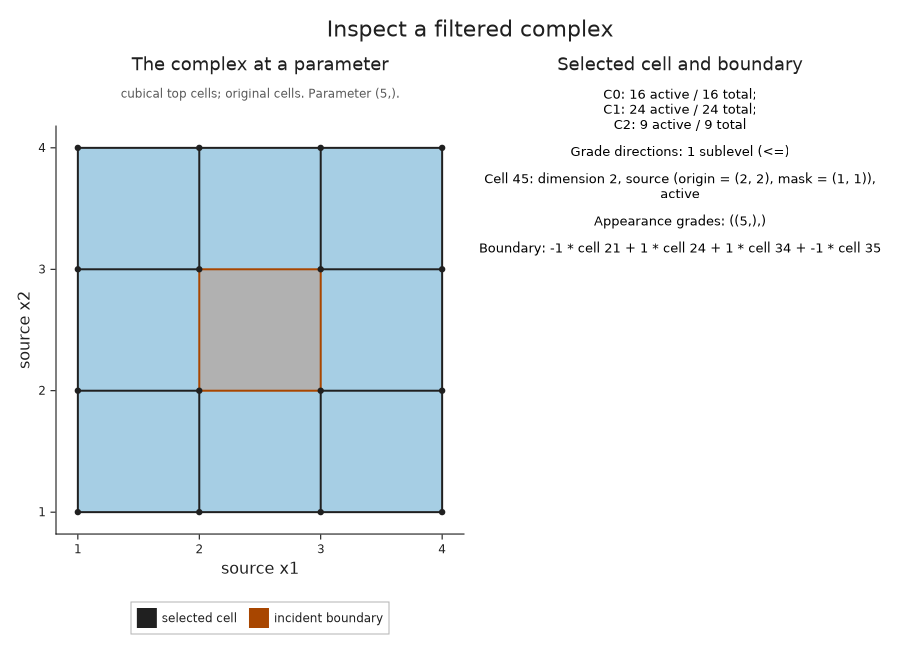

In [7]:
OP.Advanced.cell_source(cells, 45)
OP.visualize(cells; parameter=5, cell=45)


Exact parameter queries decide activity before coordinates are converted for drawing. A value just below five leaves the central square inactive even if the displayed decimal rounds to five.

Showing inactive context can be useful here. Faint cells belong to the retained input, but not to the active subcomplex.


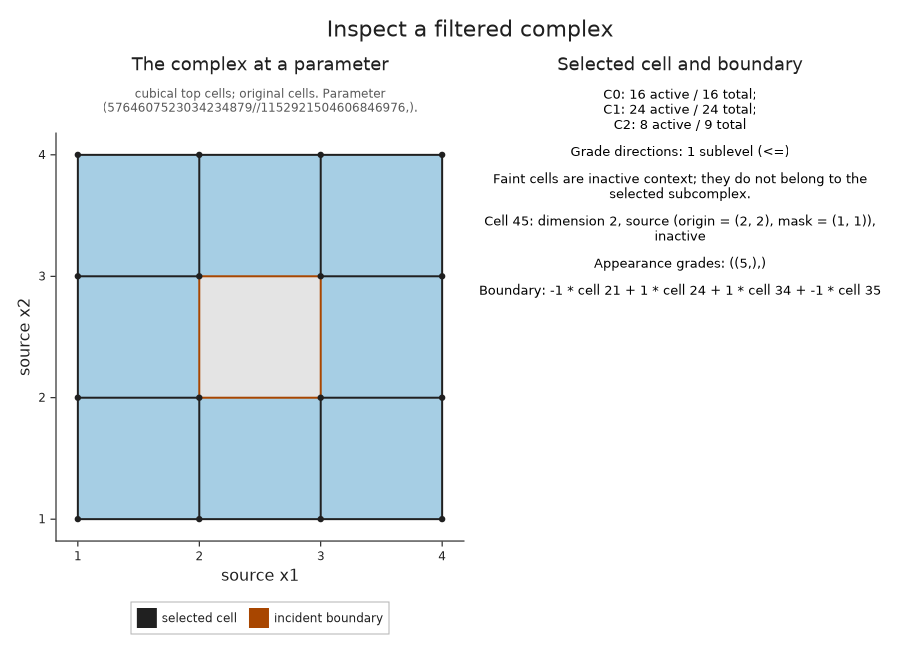

In [8]:
just_before = 5 - big(1) // big(2)^60
before = OP.Advanced.visual_spec(cells; parameter=just_before, cell=45)
@assert !before.metadata.selected.active
OP.visualize(cells; parameter=just_before, cell=45, activity=:all)


## Change the model deliberately

The same array can instead assign values to **vertices**. An edge then waits for both endpoints, and a square waits for all four vertices. Here the high center vertex delays every incident edge and square.

The two inputs have different cells, even though this small example produces a loop with the same lifetime. Compare the figure with the first one: an image array alone does not specify a filtration.


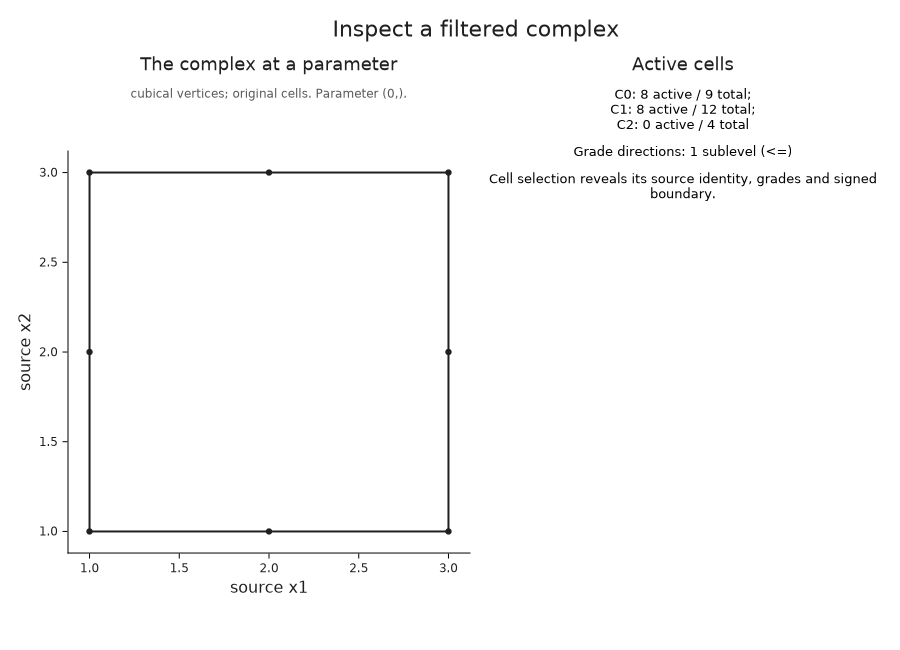

In [9]:
vertex_cells = OP.filtered_complex(values; input=:vertices)
@assert OP.Advanced.visual_spec(vertex_cells).metadata.active_counts == [8, 8, 0]
OP.visualize(vertex_cells)


A scalar overlay can show the actual supplied top-cell values at cell centers. These are samples of the filtration field, with no interpolation, binning or additional density estimate. The color scale stays fixed as the parameter changes.


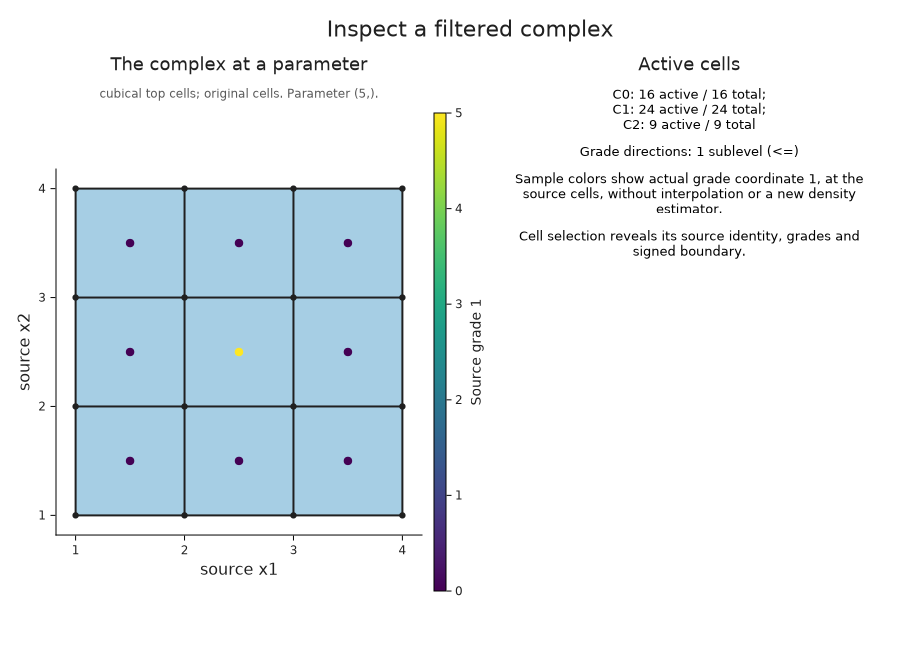

In [10]:
OP.visualize(cells; parameter=5, field_axis=1)


## Inspect the constructed point-cloud complex

A Rips filtration adds a simplex when all its pairwise distances are within the threshold. For these three points, the two shorter edges appear at one; the remaining edge and the filled triangle appear together at the diagonal distance.

The figure draws the actual constructed simplices. It does not replace them with balls or a nearby radius-graph illustration. The Rips parameter is a **diameter threshold**, not a ball radius.


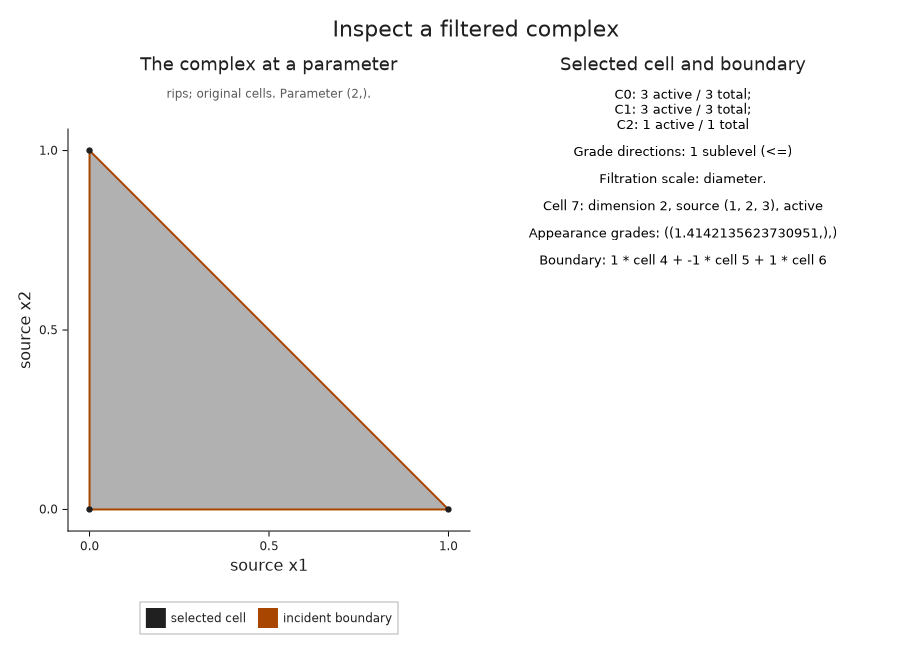

In [11]:
cloud = OP.PointCloud([0.0 0.0;
                       1.0 0.0;
                       0.0 1.0])
triangle = OP.filtered_complex(cloud, OP.RipsFiltration(max_dim=2))
@assert OP.Advanced.visual_spec(triangle; parameter=1).metadata.active_counts == [3, 2, 0]
OP.visualize(triangle; parameter=2, cell=7)


## Keep the drawing's limits visible

A periodic square has identified opposite sides. Its planar picture is a fundamental domain, not an embedding of the resulting torus. In the one-square example there is only one vertex and two edges; repeated geometric endpoints represent that same vertex. Opposite boundary incidences cancel in the cellular boundary of the square.


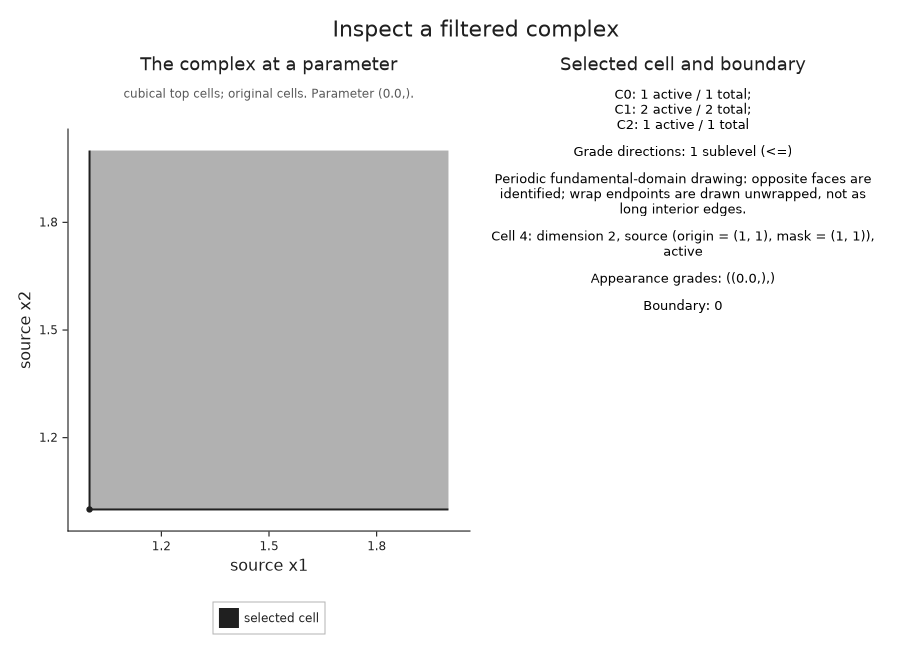

In [12]:
periodic_cell = OP.filtered_complex(zeros(1, 1); periodic=true)
periodic_view = OP.Advanced.visual_spec(periodic_cell; cell=4)
@assert periodic_view.metadata.active_counts == [1, 2, 1]
@assert isempty(periodic_view.metadata.selected.boundary)
OP.visualize(periodic_cell; cell=4)


Volumes make another distinction useful: showing the 2-skeleton does not remove higher cells from the retained complex. This cube has an active 3-cell. Its pictured faces therefore do not establish a surviving cavity.


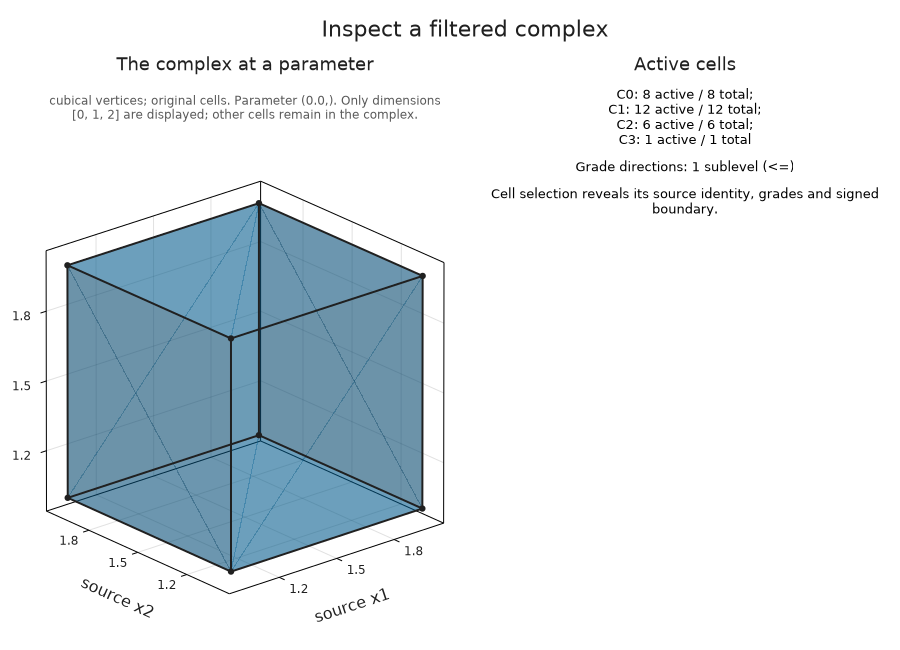

In [13]:
cube = OP.filtered_complex(zeros(2, 2, 2); input=:vertices)
@assert OP.Advanced.visual_spec(cube).metadata.active_counts == [8, 12, 6, 1]
OP.visualize(cube)


## Ask which cells represent the hole

A highlighted boundary in the cell viewer has no automatic relationship to a persistence interval. To make that connection, retain both reduction representatives and source geometry. These are separate choices: the ordinary interval-only computation needs neither.

The ring has a degree-one interval from zero to five. Select its original member and draw the returned source cycle. This query checks that the chain is active at the selected scale and that its boundary is zero on the original cells.


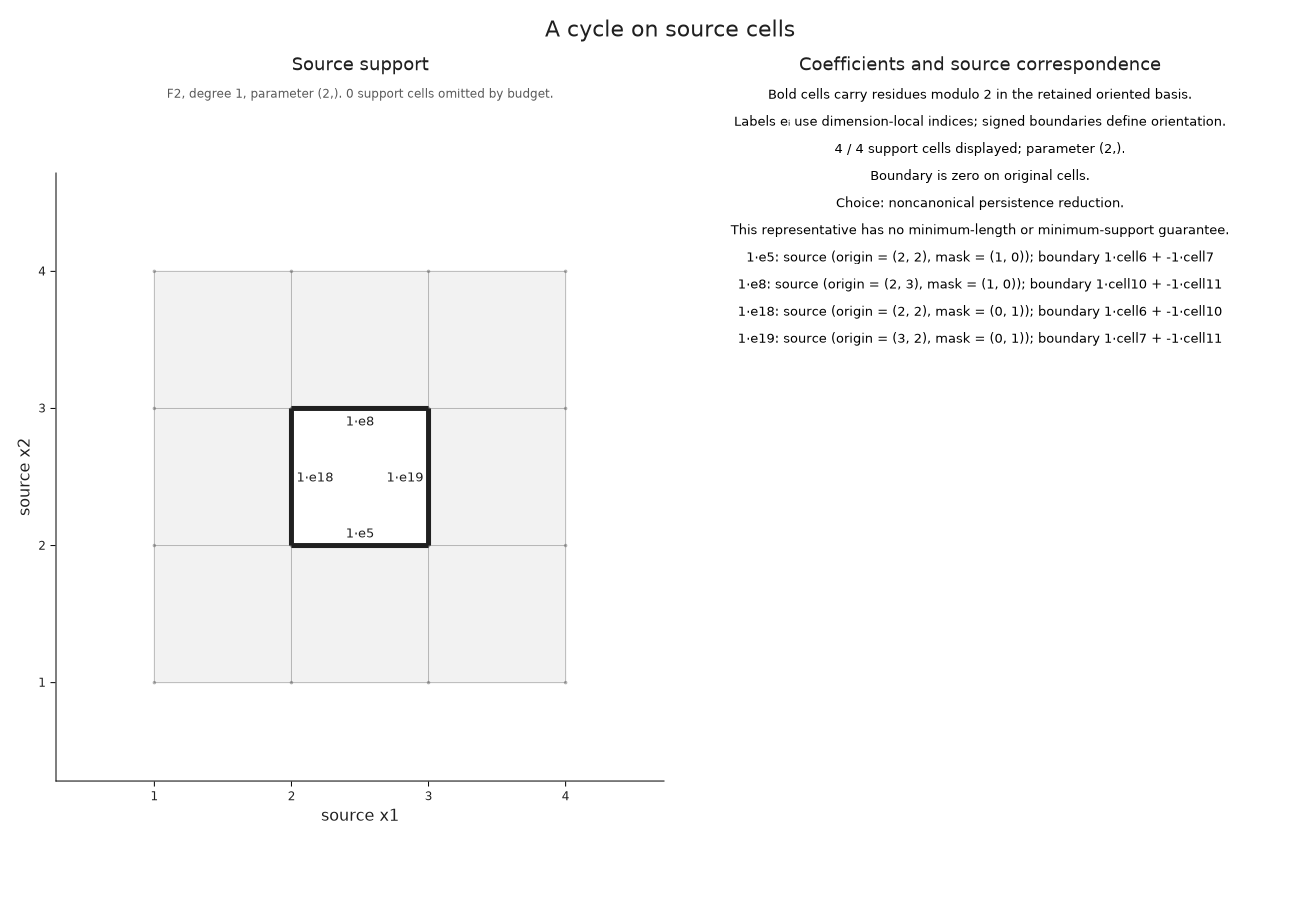

In [14]:
diagram = OP.cubical_persistence(values; representatives=true, source=true)
selected = OP.Advanced.persistence_representative(diagram; dim=1, scale=2)
@assert selected.interval == (0, 5)
@assert OP.Advanced.check_source_chain(selected.source_cycle).valid
OP.visualize(selected.source_cycle)


The coefficient labels refer to oriented cell basis vectors, rather than pixel labels or interval IDs. This is one noncanonical reduction choice. Another ordering of equal-grade cells may choose a different cycle in the same class.

At death there is a second useful object: a chain of squares whose boundary is the selected cycle. Its squares need not all be present at scale two. The next drawing deliberately uses the death parameter, five.


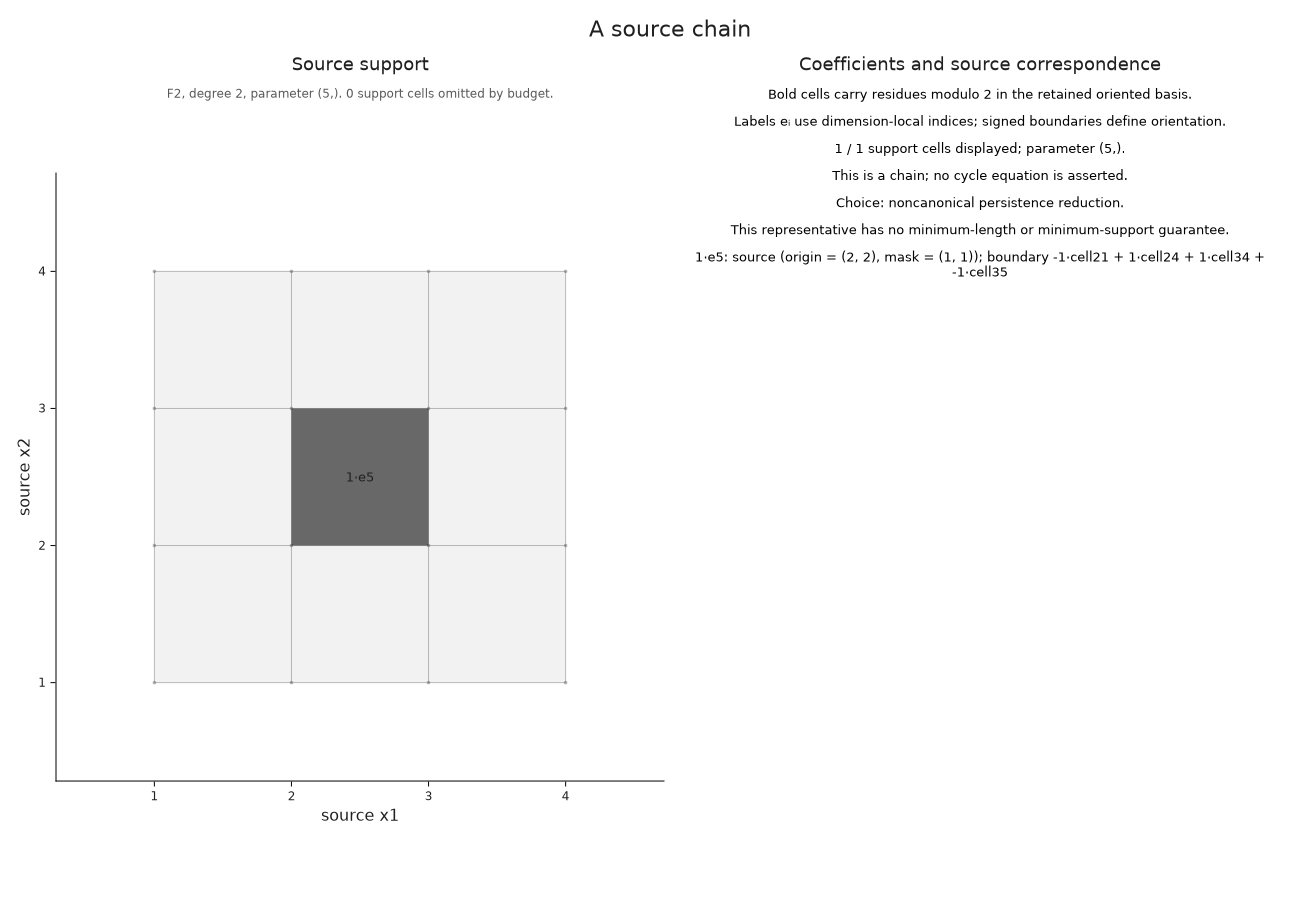

In [15]:
filling = selected.source_bounding_chain
@assert OP.describe(filling).parameter == (5,)
OP.visualize(filling)


## Measure the hole with a cocycle

A cycle is a weighted chain with zero boundary. A cocycle assigns values to cells and vanishes on active boundaries. It measures cycles; drawing its support does not turn it into a cycle. Over the field with three elements, coefficient two means minus one, so orientation matters.

Keep the source geometry and a scale-specific cochain. The cochain below annihilates boundaries of all squares active at scale two. Its validity stops at the finite death: scale five is excluded.


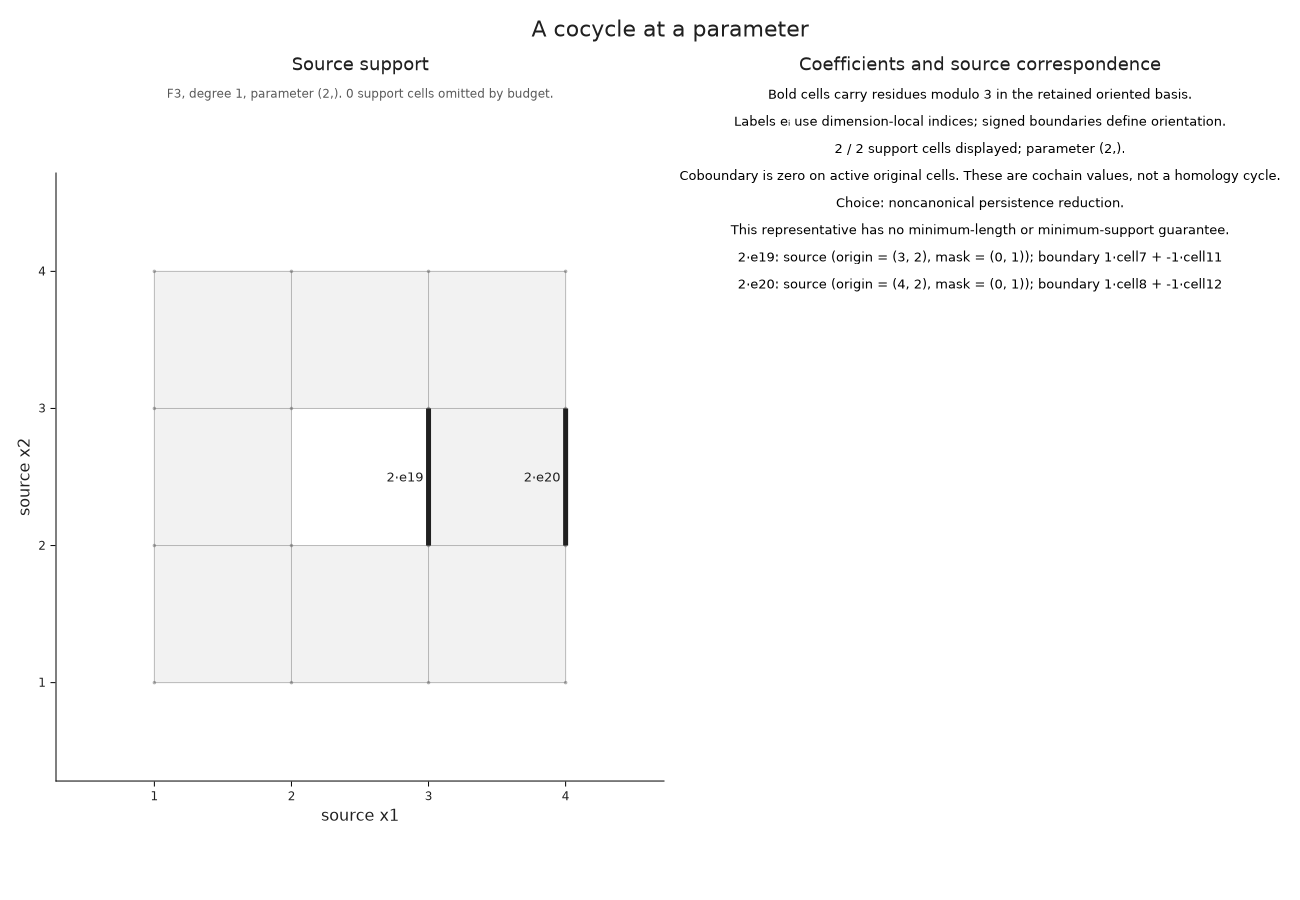

In [16]:
cohomology = OP.cubical_persistence(values; field=OP.CoreModules.F3(), cocycles=true, source=true)
measurement = OP.Advanced.persistence_cocycle(cohomology; dim=1, scale=2)
@assert OP.Advanced.check_source_chain(measurement.source_cochain).valid
OP.visualize(measurement.source_cochain)


A source correspondence is needed after reducing a complex too. Chains lift through a chain map; cocycles pull back through a retained retraction in the opposite direction. `source=true` supplies and verifies these maps for supported collapsed constructions. A barcode match alone would not justify either operation. The [implementation account](../implementation/source_representatives.md) works through a signed triangle example.

## Choose what a shorter representative means

An unqualified “shortest cycle” would leave the scale, coefficients, cell weights and allowed deformations unspecified. Here we ask a precise finite question: at scale two, minimize weighted support among all cycles homologous to our selected cycle. Give its currently used edges weight five and every other edge weight one. This encourages a different route around the same hole; the weights are a declared preference, not Euclidean lengths.

The bounded exact search enumerates the active boundary image. It refuses a problem larger than its candidate budget. Its result records a chain witnessing that the new cycle differs from the old one by a boundary, and checks that the class remains nonzero.


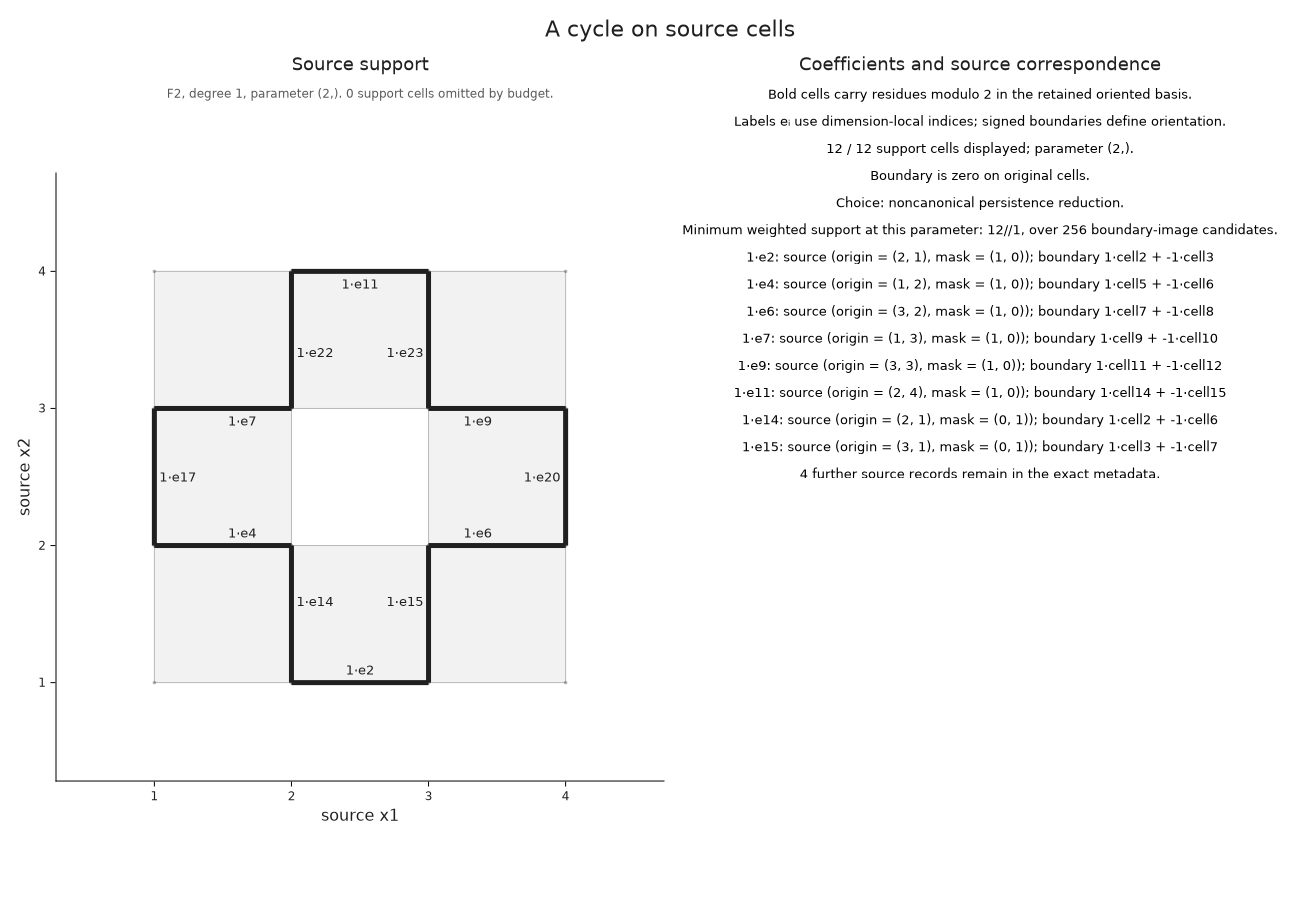

In [17]:
weights = ones(Int, OP.describe(selected.source_cycle).cell_count)
weights[collect(OP.Advanced.source_chain_data(selected.source_cycle).cell_indices)] .= 5
optimized = OP.Advanced.optimize_representative(selected.source_cycle; weights)
@assert OP.describe(optimized).metadata.nonzero_class
@assert OP.describe(optimized).metadata.objective < sum(weights[collect(OP.Advanced.source_chain_data(selected.source_cycle).cell_indices)])
OP.visualize(optimized)


Changing the parameter changes which filling chains are admissible. The guarantee above concerns only this finite complex and scale. Ordinary plotting never launches this search.

## Keep a periodic class tied to its cells

The one-square torus has two essential degree-one members with identical interval endpoints. Choose one original member explicitly. Its edge wraps across a periodic seam and has zero boundary because the endpoints are identified. The picture uses an unwrapped fundamental domain; the two drawn endpoints do not create two source vertices.


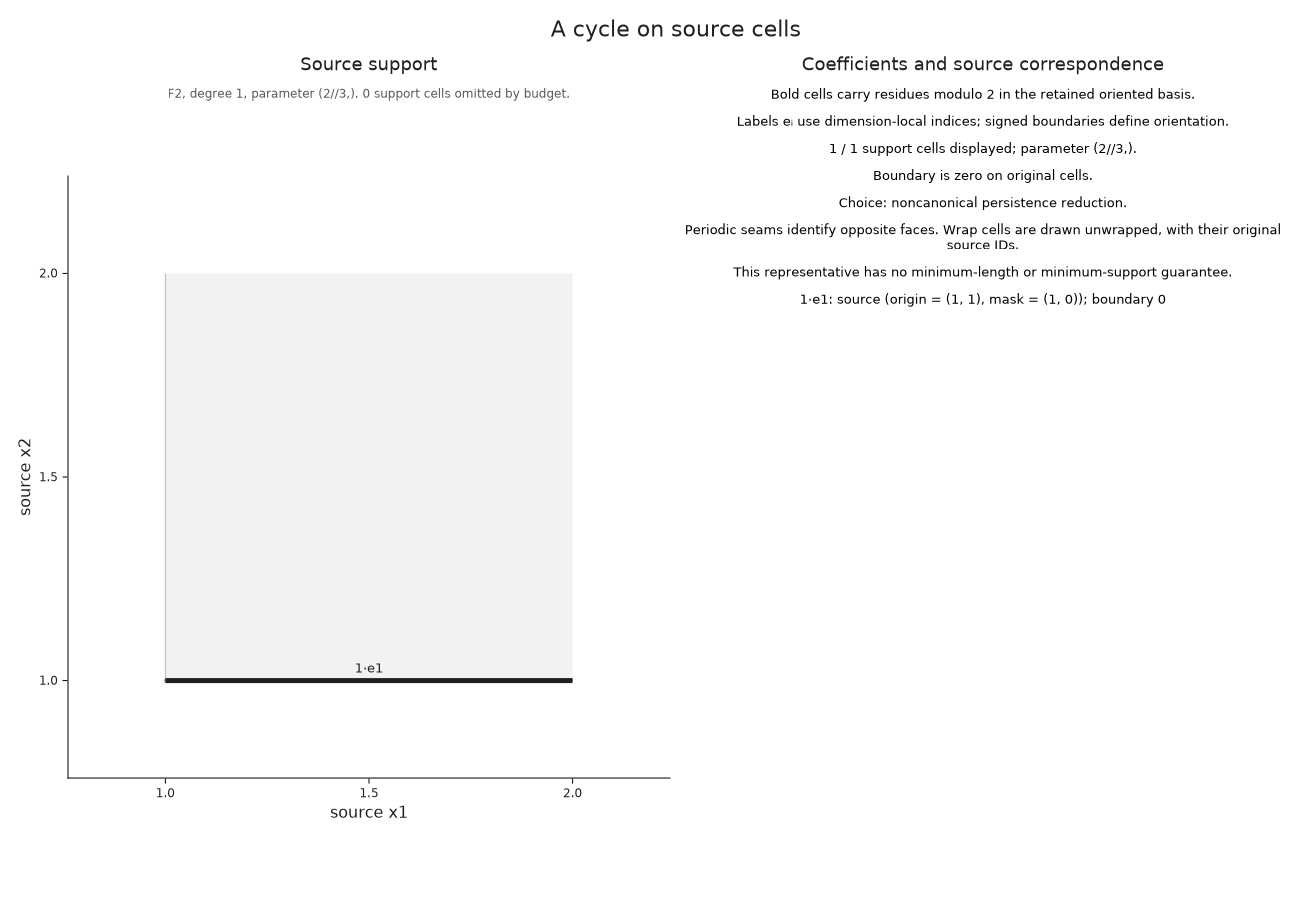

In [18]:
torus = OP.cubical_persistence(fill(2//3, 1, 1); periodic=true, representatives=true, source=true)
seam = OP.Advanced.persistence_representative(torus; dim=1, kind=:essential, index=1)
@assert OP.describe(seam.source_cycle).parameter == (2//3,)
OP.visualize(seam.source_cycle)


The same source-map contract accepts supplied cellular complexes and multiparameter or multicritical grades. Construct a `source_correspondence` from retained filtered complexes and call `lift_source_chain` with a parameter tuple and explicit coordinates. This checks a supplied chain-basis correspondence. It does not recover a missing correspondence from an arbitrary finite module, nor track a class between different slices automatically.

The finite encoding remains the junction for module spaces, maps and algebraic operations. These source records are additional retained evidence for geometric explanations. Direct ordinary persistence can use them without building a general encoding.


## Follow whole connected components

A chosen degree-zero representative can be a single vertex. The component it represents can contain many vertices and edges. To see that membership, use the source incidences themselves.

Consider two strips of squares separated by a third strip. The outer strips appear at zero, and the strip between them appears at two. Before two there are two components. At two the middle strip connects them. The merge history keeps the source vertex identities, so selecting a bar can reveal its whole component.

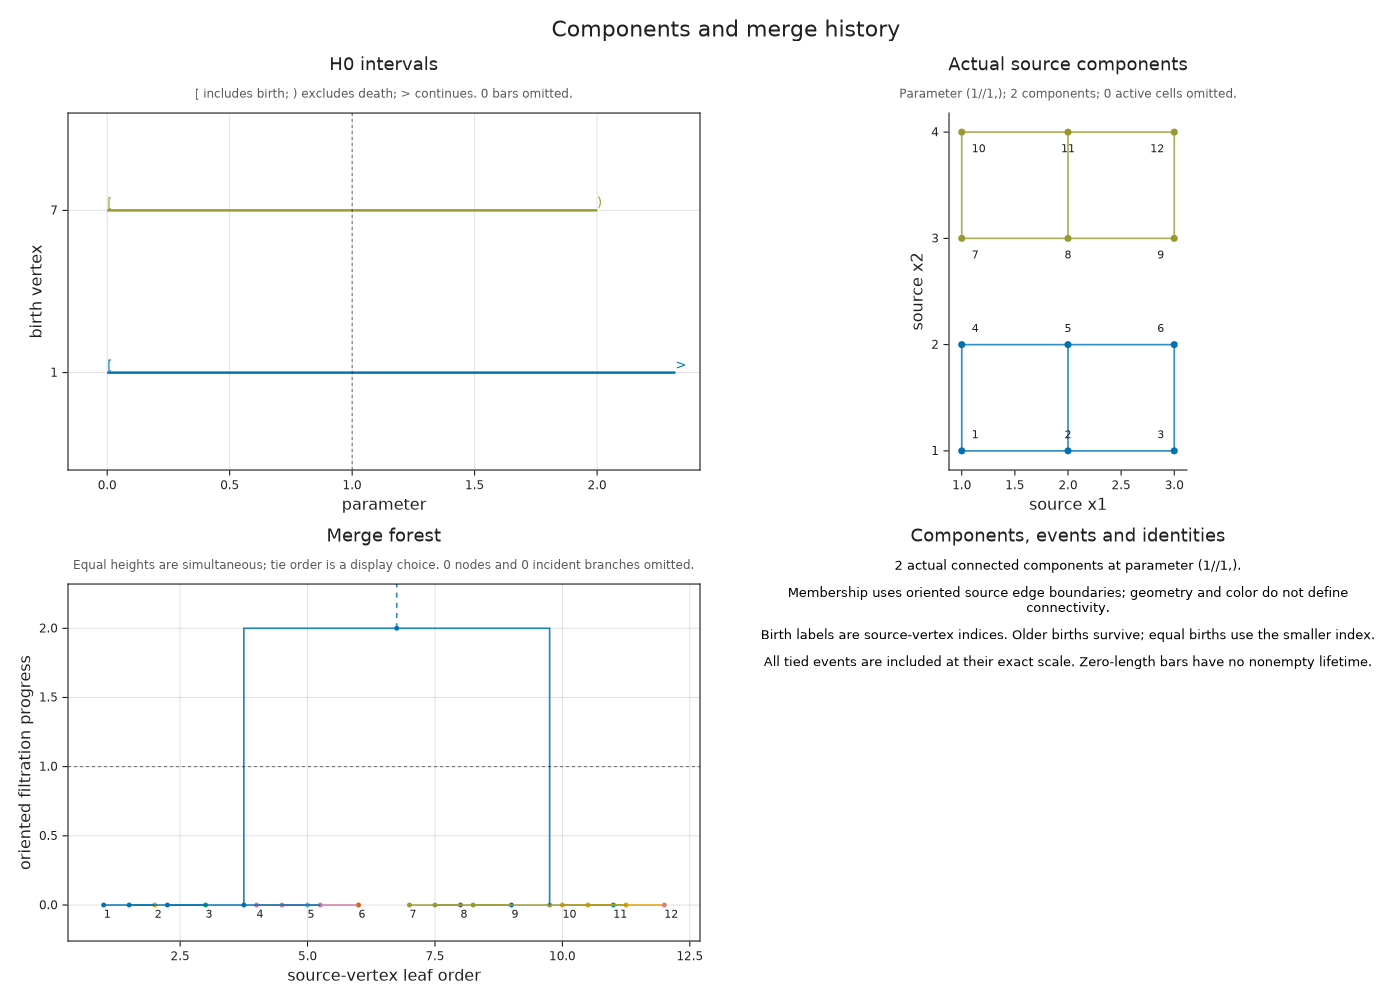

In [19]:
islands = OP.filtered_complex([0 2 0; 0 2 0])
history = OP.component_history(islands)
@assert OP.component_count(history; scale=1) == 2
@assert OP.component_count(history; scale=2) == 1
OP.visualize(history; scale=1)

The interval panel gives each bar a **birth-vertex index**. The merge forest records which components joined; the source panel shows their actual vertices and edges. A color follows the surviving birth label. Source labels and selection outlines also make the correspondence readable without color.

Select the finite bar. Just before its death, its membership is one island. At death, all events with that exact value have occurred. Its bar has ended, while its source vertices now belong to the surviving component.

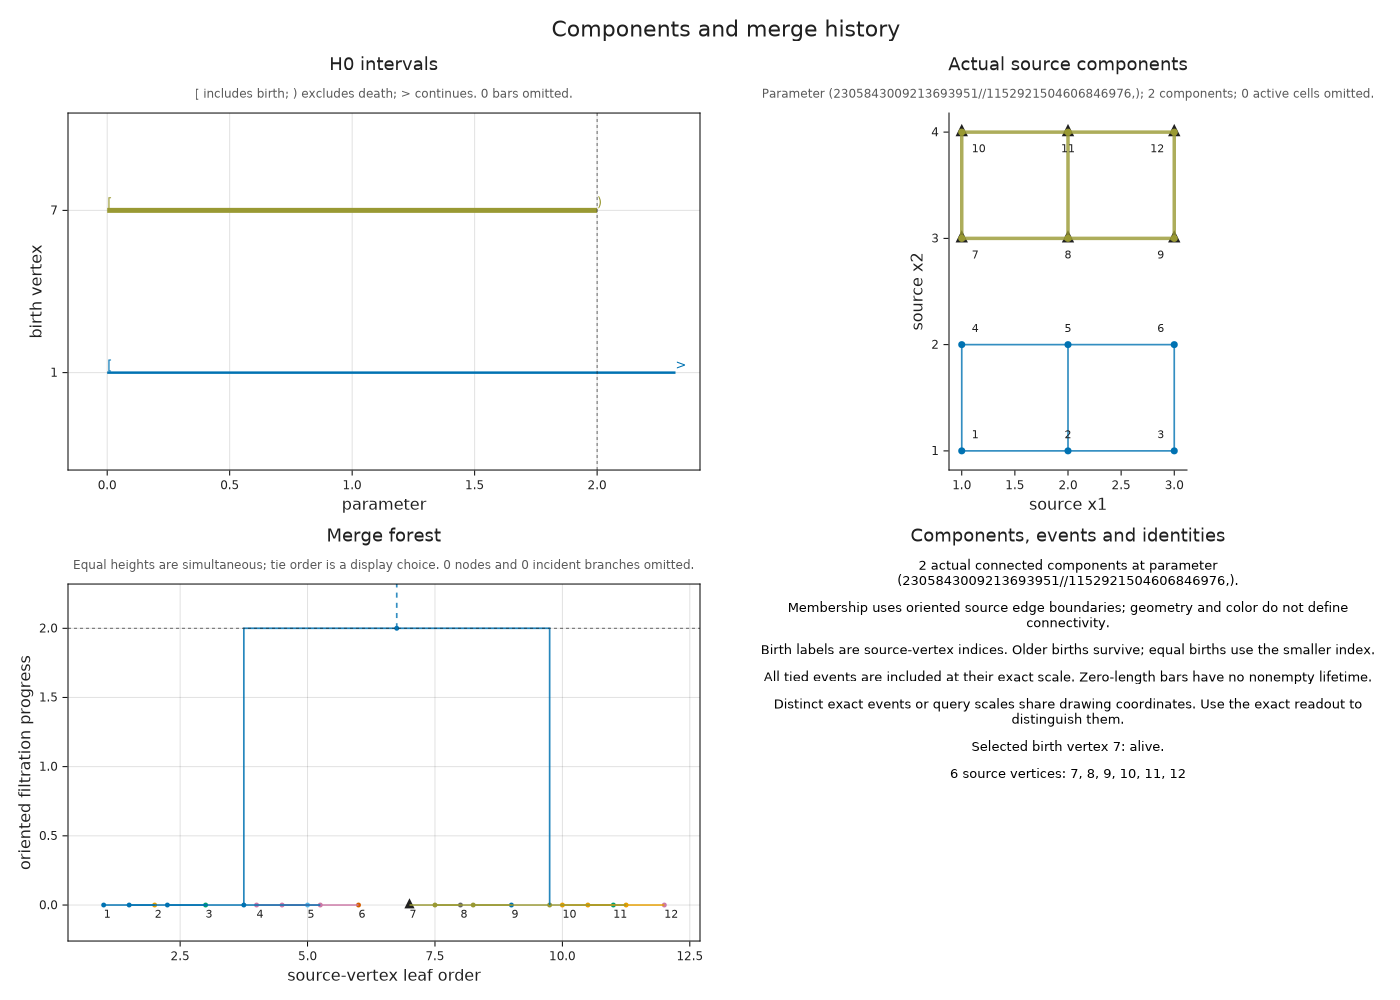

In [20]:
finite_component = only(r.component for r in OP.Advanced.component_intervals(history) if r.death !== nothing)
just_before_merge = 2 - big(1) // big(2)^60
members_before = OP.component_members(history; scale=just_before_merge, component=finite_component)
@assert members_before.status == :alive
OP.visualize(history; scale=just_before_merge, component=finite_component)

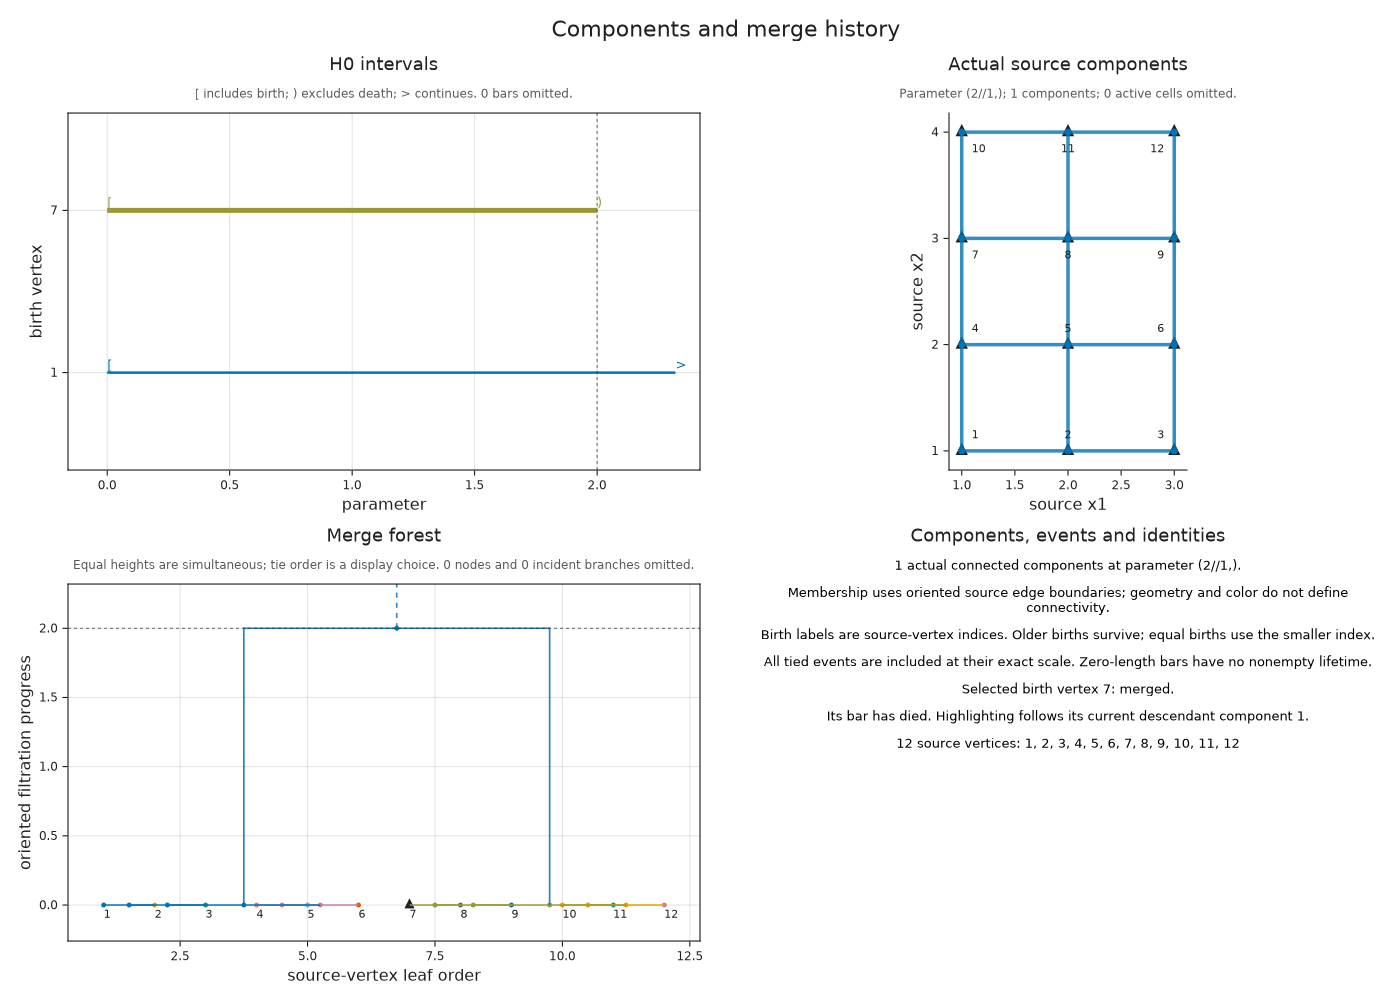

In [21]:
members_after = OP.component_members(history; scale=2, component=finite_component)
@assert members_after.status == :merged
@assert length(members_after.vertices) > length(members_before.vertices)
OP.visualize(history; scale=2, component=finite_component)

The readout now says **merged**: the highlighted descendant does not extend the dead bar's lifetime. `components_at(history; scale=...)` returns the complete partition when you need all memberships. `component_count` answers the smaller counting question without listing the vertex sets.

Several cells can enter together. The resulting partition after the event is fixed, but a binary ordering of those simultaneous merges is a display choice. The history uses the older birth first and the smaller birth-vertex index to break ties. Empty, zero-length bars are hidden by default; `show_ephemeral=true` includes them explicitly. None has a nonempty interval of survival.

## Choose a slice before asking for a merge tree

For several parameters, choose an oriented affine line `p(t) = base + t * direction`. Different lines can give different merge histories. Every direction coordinate must advance in its source coordinate's declared order.

Here the two vertices exist at `(0,0)`. Their connecting edge appears at either `(1,3)` or `(3,1)`. The diagonal reaches that union at `t=3`. The line `(t,2t)` reaches it at `t=3/2`; filling the rectangular hull of those two grades would give the wrong answer.

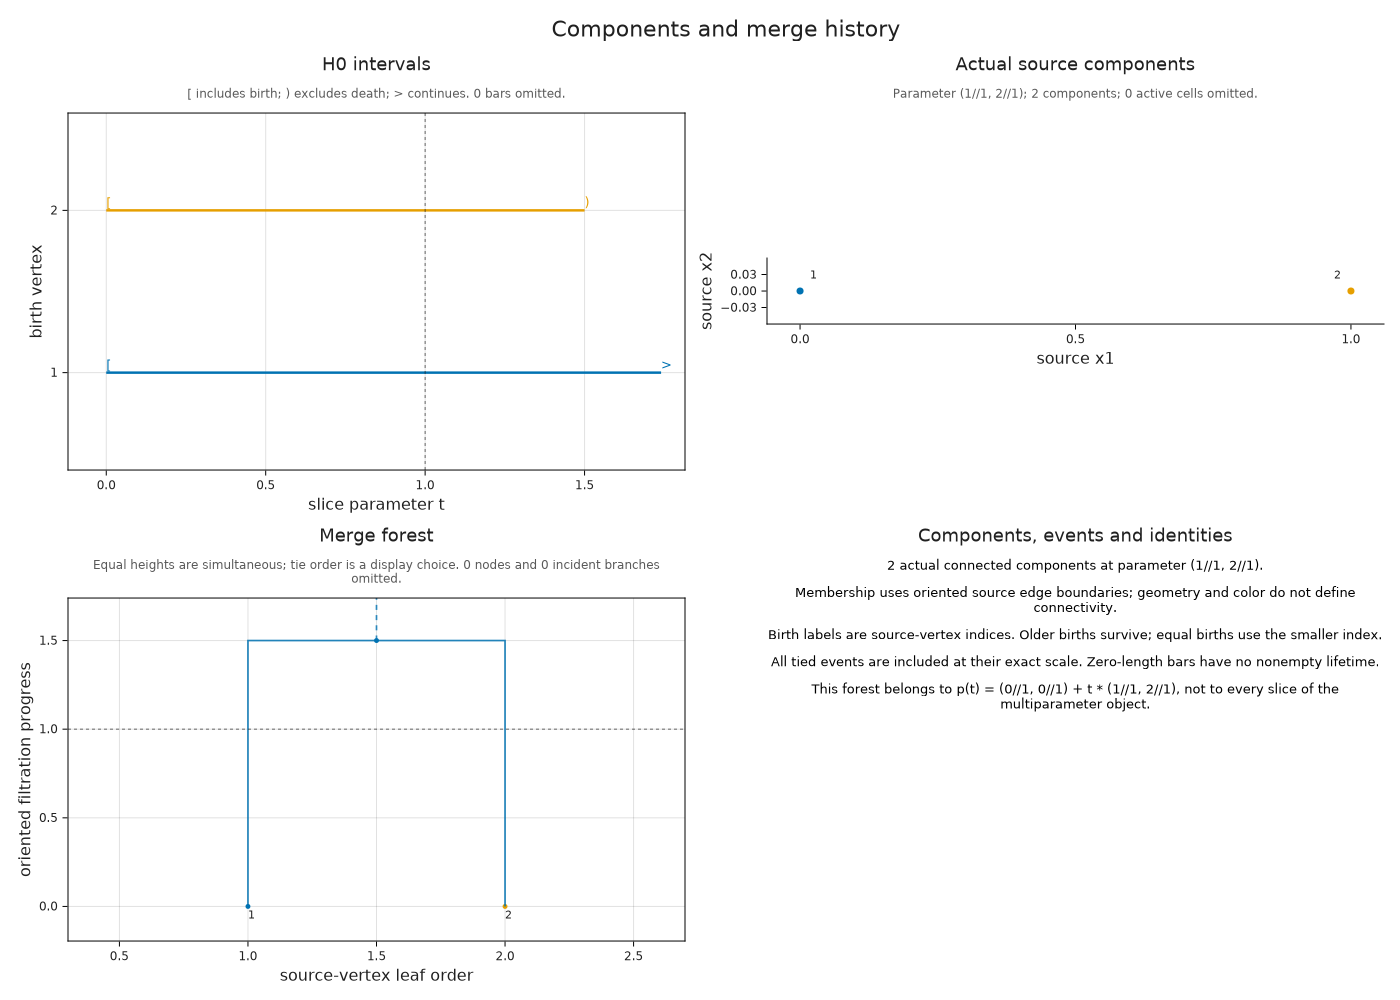

In [22]:
import SparseArrays
multi_graph = OP.DataTypes.MultiCriticalGradedComplex(
    [[1, 2], [3]], [SparseArrays.sparse(reshape([-1, 1], 2, 1))],
    [[(0, 0)], [(0, 0)], [(1, 3), (3, 1)]])
multi_source = OP.filtered_complex(multi_graph;
    geometry=[[(0, 0)], [(1, 0)], [(0, 0), (1, 0)]])
slanted = OP.component_history(multi_source; slice=(base=(0, 0), direction=(1, 2)))
@assert only(OP.Advanced.component_merges(slanted)).scale == 3 // 2
OP.visualize(slanted; scale=1)

Try the diagonal direction `(1,1)` and predict the component count at `t=2` before querying it. There are still two components. The exact source parameter is available through `component_parameter`; its coordinates need not equal the slice parameter.

For superlevel inputs, ordinary scales remain in the original units. The charts use increasing oriented progress, labelled `-parameter`, so descending thresholds run in the direction of the filtration. Membership always uses the actual threshold. A retained-source persistence diagram can also supply `component_history(diagram)`: its original-source H₀ interval multiset is checked, while repeated equal bars retain the ambiguity of individual reduction-basis choices.

## Explore with linked controls

For a live Julia-backed browser view, activate WGLMakie and create a session:

```julia
import WGLMakie
session = OP.inspection_session(cells)
OP.visualize(session; backend=:wglmakie)
```

Move the grade slider from 0 toward 5 and watch the eight outer squares remain while the centre is still absent. The **Next event** button takes us exactly to 5, where the central square enters. Cells with the same grade enter together; a pointer position near 5 need not be exactly 5. The text field accepts a fraction when that distinction matters.

The readout gives the committed parameter and active counts alongside the totals. While a new query is pending, the picture continues to describe the committed value. **Show inactive context** adds faint cells outside the selected subcomplex, which helps us see what remains to appear. For two varying coordinates, the square in the parameter plane provides another way to move through the filtration. Sliders have arrow-key controls, and event buttons follow the declared sublevel or superlevel direction.

Select a cell near its center or by its exact index, and inspect its grades and boundary. The dimension controls filter the drawing. They do not change the retained complex. Two calls to `visualize(session)` create independent views sharing the selection.

Use `OP.Advanced.inspection_snapshot(session)` for a static figure and `OP.Advanced.close_inspection!(session)` when finished. The final snapshot remains available after closure.

The ordinary interval inspector can share an original member selection with its available source cycle and death filling:

```julia
intervals = OP.inspection_session(diagram; dim=1)
OP.visualize(intervals; backend=:wglmakie)
```

Select a group and member, then enable **Show retained representative**. The source cycle is shown at birth and the filling at death. Resetting clears the overlays; closing releases the live callbacks. An endpoint-only diagram reports that representatives are unavailable.

The component history has its own linked view:

```julia
components = OP.inspection_session(history; scale=1)
OP.visualize(components; backend=:wglmakie)
```

Select a bar, a source vertex or a merge node. The event buttons move among exact source events; selecting a merge moves to its scale and identifies the edge that joined the components. An independent linked view shares the same selection. Close it with `OP.Advanced.close_inspection!(components)` when finished. The [component reference](../src/reference/source_representatives.md#components-and-merge-histories) explains identities, source requirements and tie conventions.

## Follow the source question

Try `order=:superlevel` on the image. Predict why the central square appears before its surroundings, then inspect the boundary faces it brings with it. For several parameters, supply a tuple; a multicritical cell is active if **any** of its appearance grades precedes that tuple in the declared coordinate orientations.

The [visualization reference](../src/reference/visualization.md#filtered-complexes-and-source-cells) gives the exact contracts for supplied cellular geometry, display budgets and coordinate projections. Continue with [ordinary persistence](../ordinary_persistence.md) to choose an input-to-interval construction. For precise map, cochain and optimization guarantees, use the [source representative reference](../src/reference/source_representatives.md).
